# Drone Tespit ve Takibi — YOLO11 + ByteTrack

Bu notebook projenin tamamını Google Colab'da baştan sona çalıştırır:
1. Veri setini indirme ve hazırlama
2. YOLO11n eğitimi
3. Test setinde değerlendirme (boyuta göre recall dahil)
4. Videoda ByteTrack ile takip
5. ONNX'e çevirme ve CPU hız ölçümü

**Başlamadan önce:** Çalışma Zamanı → Çalışma zamanı türünü değiştir → **T4 GPU** seç.

In [12]:
!nvidia-smi --query-gpu=name,memory.total --format=csv
!git clone https://github.com/semanur-s/drone-detection-tracking.git
%cd drone-detection-tracking
!pip install -q -r requirements.txt

name, memory.total [MiB]
Tesla T4, 15360 MiB
Cloning into 'drone-detection-tracking'...
remote: Enumerating objects: 30, done.
remote: Counting objects: 100% (30/30), done.
remote: Compressing objects: 100% (28/28), done.
remote: Total 30 (delta 5), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (30/30), 21.10 KiB | 7.03 MiB/s, done.
Resolving deltas: 100% (5/5), done.
/content/drone-detection-tracking/drone-detection-tracking/drone-detection-tracking


## (İsteğe bağlı) Sonuçları Google Drive'a kaydet
Colab oturumu kapanınca dosyalar silinir. Drive'ı bağlarsan eğitim çıktıları kaybolmaz.

In [13]:
from google.colab import drive
drive.mount('/content/drive')
SAVE_DIR = '/content/drive/MyDrive/drone-detection-tracking'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Veri setini hazırla
Seraphim Drone Detection Dataset (CC BY 4.0) zip'lenmiş batch'ler halinde tutuluyor. Tamamı ~9 GB olduğu için ilk birkaç batch'i indiriyoruz. Eğitimden %10 doğrulama seti ayrılır, test seti ayrı kalır.

In [14]:
!python src/prepare_data.py --train-batches 1 --test-batches 1 --max-train 8000 --max-test 2000 --out data

Train batch'leri indiriliyor...

train/images/batch_001.zip: downloading bytes:   8% 173M/2.16G [00:04<00:36, 54.7MB/s, 13.6MB/s  ]
train/images/batch_001.zip: reconstructing file:   0% 1.02M/2.16G [00:04<2:38:19, 227kB/s]
train/images/batch_001.zip: downloading bytes:   8% 183M/2.16G [00:04<00:37, 52.1MB/s, 14.3MB/s  ]
train/images/batch_001.zip: downloading bytes:   9% 189M/2.16G [00:04<00:43, 45.5MB/s, 15.0MB/s  ]
train/images/batch_001.zip: reconstructing file:   3% 65.2M/2.16G [00:04<01:13, 28.6MB/s, 3.06MB/s  ]
train/images/batch_001.zip: downloading bytes:   9% 201M/2.16G [00:05<00:39, 49.2MB/s, 15.3MB/s  ]
train/images/batch_001.zip: downloading bytes:  10% 209M/2.16G [00:05<00:42, 45.8MB/s, 16.0MB/s  ]
train/images/batch_001.zip: downloading bytes:  10% 214M/2.16G [00:05<00:41, 47.4MB/s, 16.2MB/s  ]
train/images/batch_001.zip: downloading bytes:  10% 222M/2.16G [00:05<00:37, 52.0MB/s, 16.6MB/s  ]
train/images/batch_001.zip: downloading bytes:  11% 243M/2.16G [00:05<00:26, 72.3

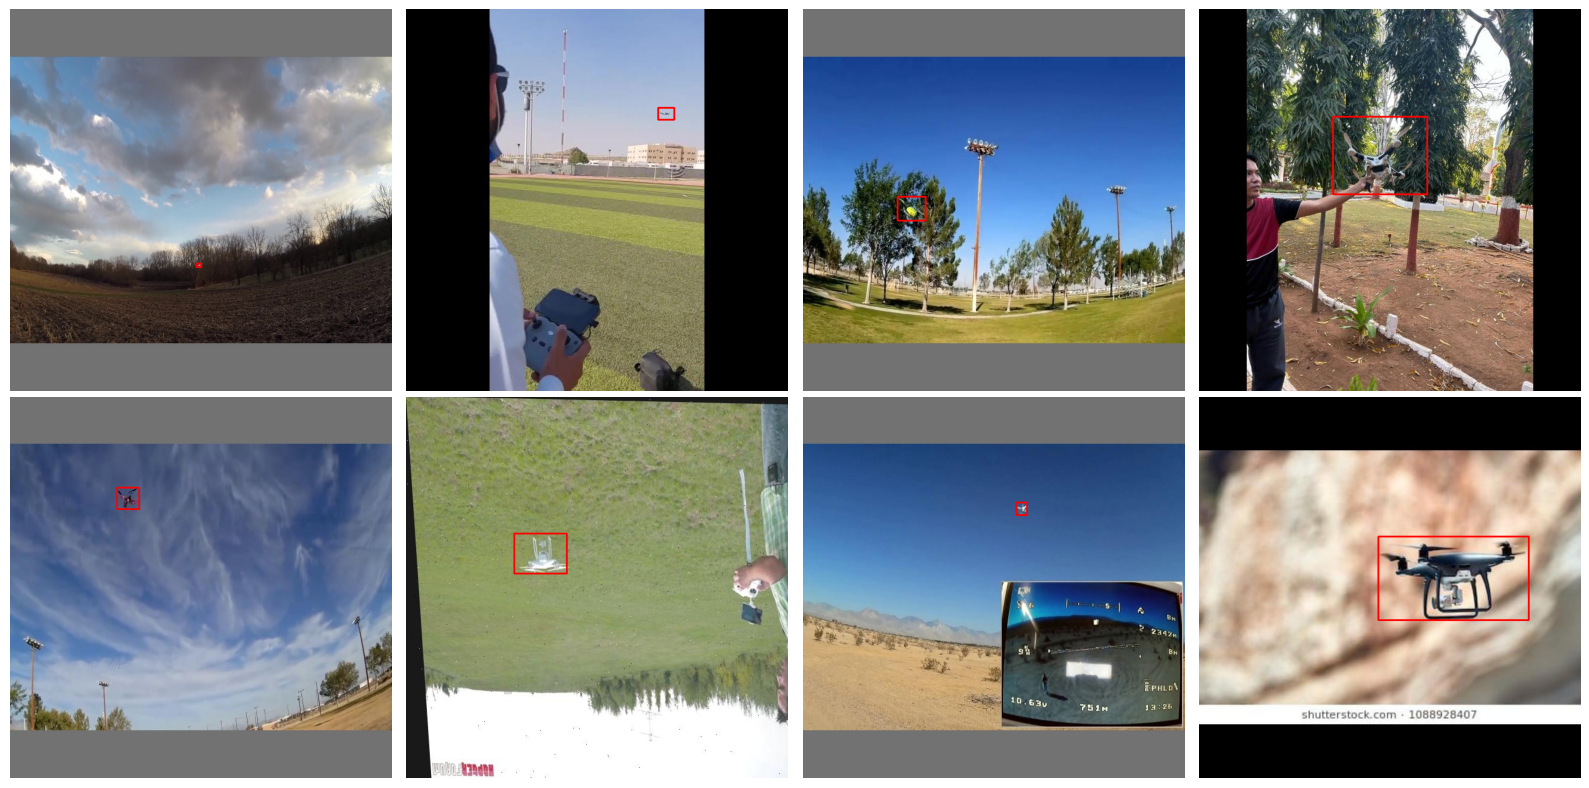

In [15]:
# Birkaç örnek görüntüyü etiketleriyle gör
import cv2, random, matplotlib.pyplot as plt
from pathlib import Path
import os; os.makedirs('assets', exist_ok=True)
IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
imgs = sorted(p for p in Path('data/drone/train/images').iterdir() if p.suffix.lower() in IMG_EXT)
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, p in zip(axes.ravel(), random.Random(0).sample(imgs, 8)):
    im = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB); h, w = im.shape[:2]
    lbl = p.parent.parent / 'labels' / (p.stem + '.txt')
    for line in (lbl.read_text().splitlines() if lbl.exists() else []):
        _, cx, cy, bw, bh = map(float, line.split())
        x1, y1 = int((cx - bw/2) * w), int((cy - bh/2) * h)
        cv2.rectangle(im, (x1, y1), (int(x1 + bw*w), int(y1 + bh*h)), (255, 0, 0), 2)
    ax.imshow(im); ax.axis('off')
plt.tight_layout(); plt.savefig('assets/ornek_veriler.png', dpi=100); plt.show()

## 2. Eğitim
COCO'da önceden eğitilmiş YOLO11n ağırlıklarıyla başlayıp drone sınıfı için ince ayar yapıyoruz. T4 GPU'da veri miktarına göre yaklaşık 30–60 dakika sürer.

In [16]:
!git pull
!rm -rf data

Already up to date.


In [19]:
!python src/train.py --data data/drone.yaml --model yolo11n.pt --epochs 50 --imgsz 640 --batch 16 --device 0
WEIGHTS = open('results/best_weights.txt').read().strip()
print(WEIGHTS)

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data/drone.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=drone_yolo11n, nbs=64, nms=None, opset=None, optimize=False, optimizer=au

In [18]:
%cd /content
!rm -rf /content/drone-detection-tracking
!git clone https://github.com/semanur-s/drone-detection-tracking.git
%cd /content/drone-detection-tracking
!pip install -q -r requirements.txt
!python src/prepare_data.py --train-batches 1 --test-batches 1 --max-train 8000 --max-test 2000 --out data
!ls data

/content
Cloning into 'drone-detection-tracking'...
remote: Enumerating objects: 30, done.
remote: Counting objects: 100% (30/30), done.
remote: Compressing objects: 100% (28/28), done.
remote: Total 30 (delta 5), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (30/30), 21.10 KiB | 21.10 MiB/s, done.
Resolving deltas: 100% (5/5), done.
/content/drone-detection-tracking
Train batch'leri indiriliyor...

train/images/batch_001.zip: downloading bytes:   0% 279k/2.16G [00:02<4:23:33, 137kB/s]
train/images/batch_001.zip: downloading bytes:   3% 63.9M/2.16G [00:02<00:33, 63.4MB/s, 3.74MB/s  ]
train/images/batch_001.zip: downloading bytes:   6% 120M/2.16G [00:03<00:30, 67.6MB/s, 10.3MB/s  ]
train/images/batch_001.zip: downloading bytes:   6% 130M/2.16G [00:03<00:36, 56.1MB/s, 10.9MB/s  ]
train/images/batch_001.zip: downloading bytes:   6% 140M/2.16G [00:03<00:41, 48.3MB/s, 11.7MB/s  ]
train/images/batch_001.zip: downloading bytes:  10% 213M/2.16G [00:05<00:31, 61.3MB/s, 16.2

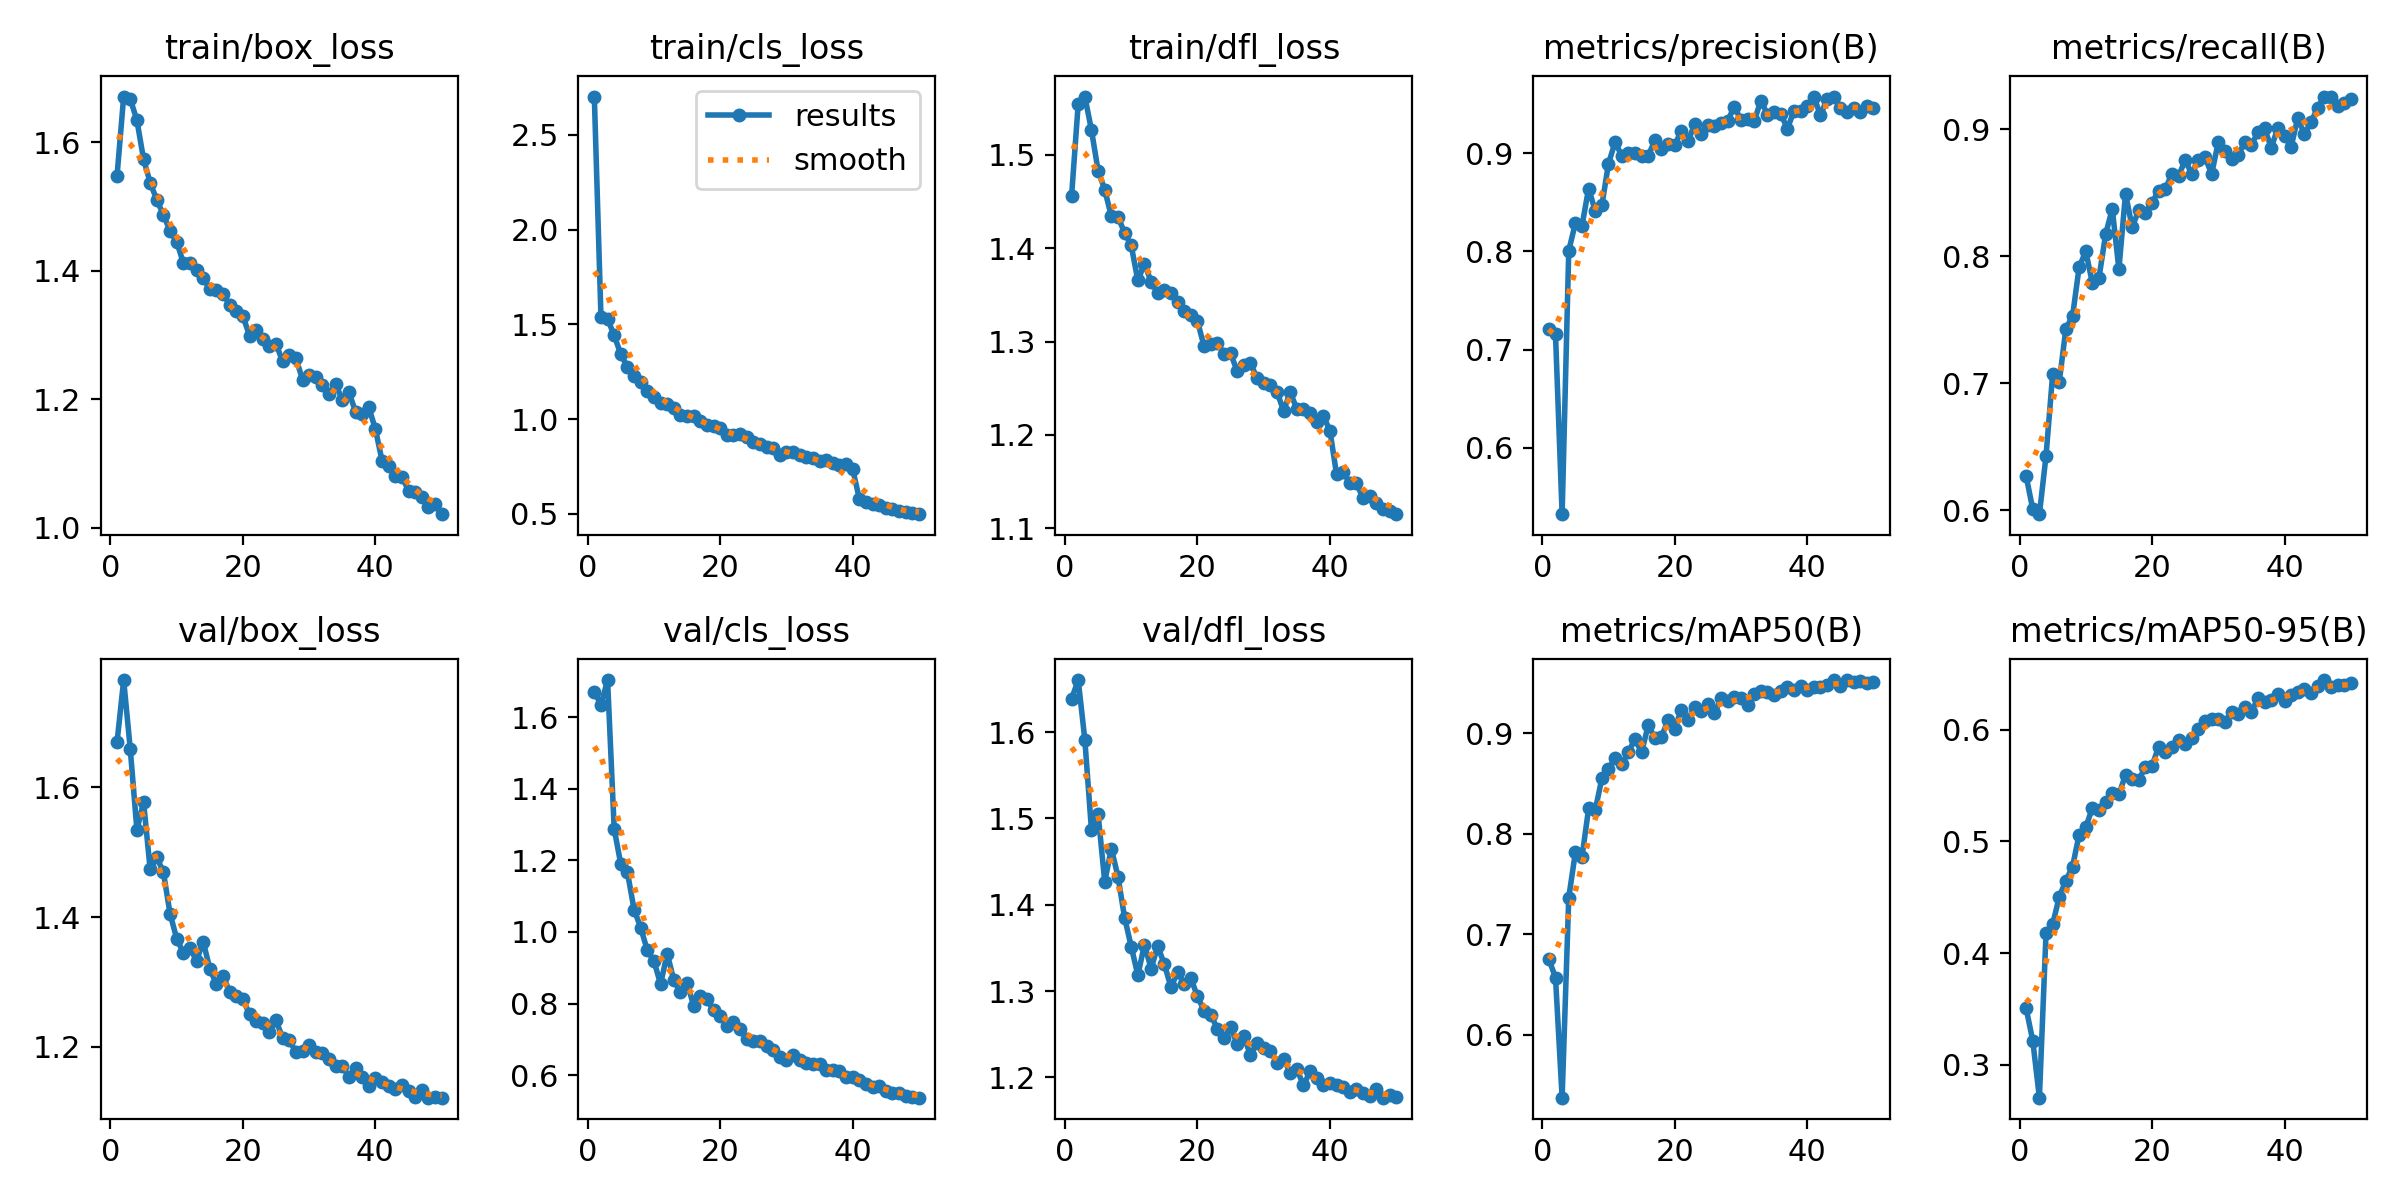

'assets/egitim_egrileri.png'

In [22]:
# Eğitim eğrileri (kayıp, precision, recall, mAP)
from IPython.display import Image, display
run_dir = Path(WEIGHTS).parent.parent
display(Image(str(run_dir / 'results.png'), width=1000))
import shutil; shutil.copy(run_dir / 'results.png', 'assets/egitim_egrileri.png')

In [21]:
import os; os.makedirs('assets', exist_ok=True)
shutil.copy(run_dir / 'results.png', 'assets/egitim_egrileri.png')

'assets/egitim_egrileri.png'

## 3. Test setinde değerlendirme
Toplam mAP'in yanında küçük / orta / büyük drone'lar için ayrı recall hesaplanır. Uzaktaki drone'lar çok küçük göründüğü için asıl zorluk küçük grupta.

In [23]:
!python src/evaluate.py --weights $WEIGHTS --data data/drone.yaml

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 37.1±29.5 MB/s, size: 92.8 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drone-detection-tracking/data/drone/test/labels... 2000 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2000/2000 587.5it/s 3.4s
val: New cache created: /content/drone-detection-tracking/data/drone/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 125/125 5.6it/s 22.4s
                   all       2000       2065      0.927      0.828      0.889      0.576
Speed: 1.4ms preprocess, 3.9ms inference, 0.0ms loss, 1.7ms postprocess per image
Results saved to /content/drone-detection-tracking/ru

In [24]:
p = 'src/evaluate.py'; s = open(p).read()
s = s.replace("for res in model.predict(source=[str(p) for p in images], conf=conf, stream=True, verbose=False):",
              "for res in (r for p in images for r in model.predict(str(p), conf=conf, verbose=False)):")
open(p, 'w').write(s)
!python src/evaluate.py --weights $WEIGHTS --data data/drone.yaml

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2130.6±789.7 MB/s, size: 103.4 KB)
val: Scanning /content/drone-detection-tracking/data/drone/test/labels.cache... 2000 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2000/2000 419.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 125/125 5.4it/s 23.3s
                   all       2000       2065      0.927      0.828      0.889      0.576
Speed: 1.4ms preprocess, 3.8ms inference, 0.0ms loss, 1.8ms postprocess per image
Results saved to /content/drone-detection-tracking/runs/detect/test_eval
{
  "precision": 0.9270673025794216,
  "recall": 0.8280871670702179,
  "mAP50": 0.8894584210880618,
  "mAP50_95": 0.5755194201772895,
  "boyuta_gore": {
    "kucuk (<32px)": {
      "adet": 446,
      "recall": 

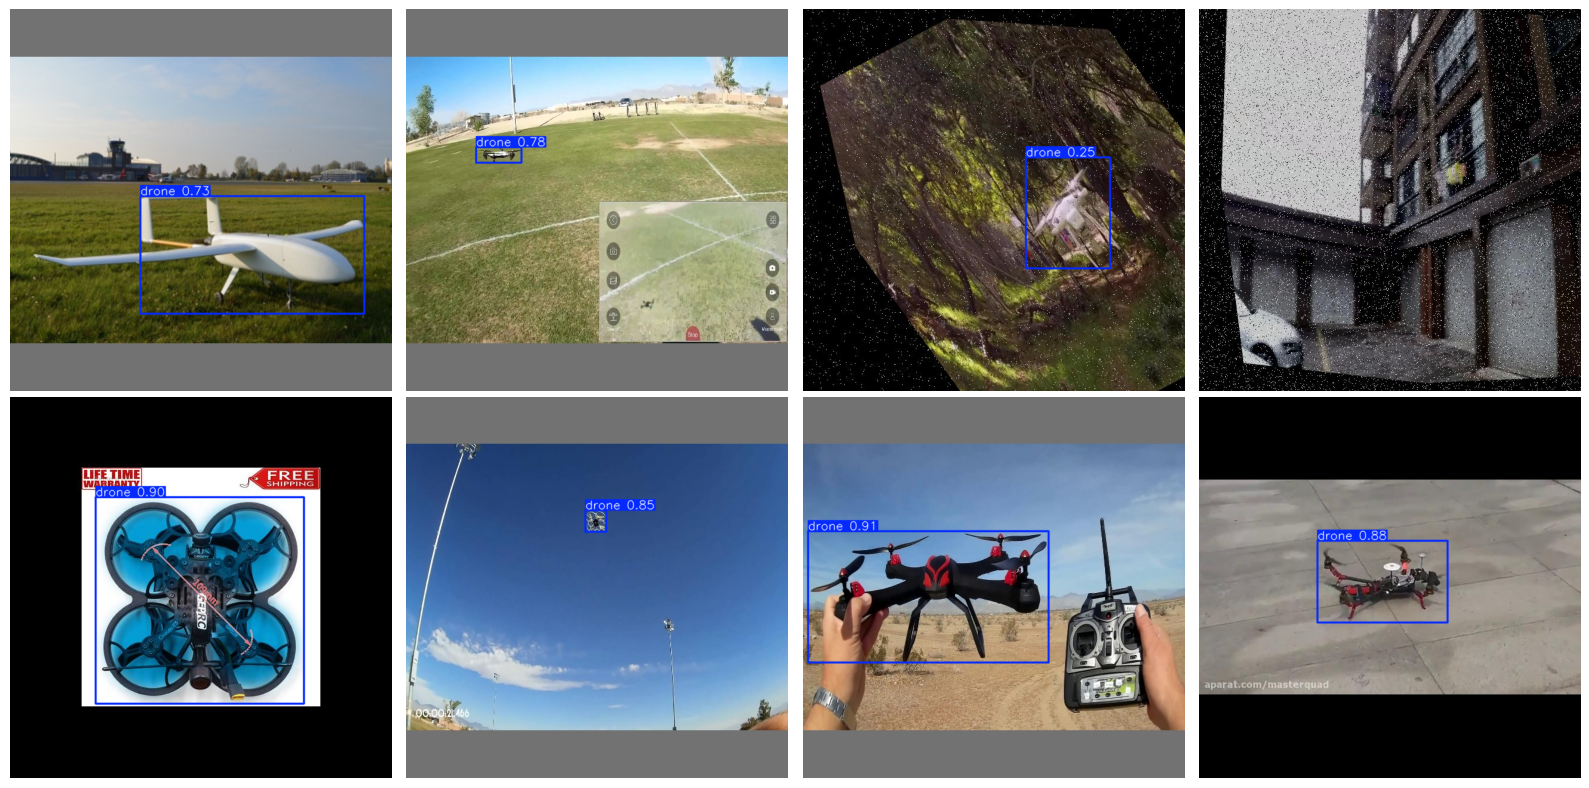

'assets/pr_egrisi.png'

In [25]:
# Test tahminlerinden örnekler
from ultralytics import YOLO
model = YOLO(WEIGHTS)
test_imgs = sorted(p for p in Path('data/drone/test/images').iterdir() if p.suffix.lower() in IMG_EXT)
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, p in zip(axes.ravel(), random.Random(1).sample(test_imgs, 8)):
    r = model.predict(str(p), conf=0.25, verbose=False)[0]
    ax.imshow(cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB)); ax.axis('off')
plt.tight_layout(); plt.savefig('assets/test_tahminleri.png', dpi=100); plt.show()
shutil.copy(Path('runs/detect/test_eval/confusion_matrix.png'), 'assets/confusion_matrix.png') if Path('runs/detect/test_eval/confusion_matrix.png').exists() else None
shutil.copy(Path('runs/detect/test_eval/BoxPR_curve.png'), 'assets/pr_egrisi.png') if Path('runs/detect/test_eval/BoxPR_curve.png').exists() else None

## 4. Videoda takip (ByteTrack)
Bir drone videosu yükle. Ücretsiz lisanslı drone videoları için Pexels'te "drone flying sky" araması yapabilirsin. Gökyüzünde uçan bir drone'un **göründüğü** videolar seçilmeli, drone'dan çekilmiş videolar değil.

In [26]:
from google.colab import files
up = files.upload()
VIDEO = list(up.keys())[0]
print(VIDEO)

Saving 14107322_2160_3840_30fps.mp4 to 14107322_2160_3840_30fps.mp4
14107322_2160_3840_30fps.mp4


In [27]:
!python src/track.py --weights $WEIGHTS --source "$VIDEO" --tracker configs/bytetrack_drone.yaml

{
  "kare_sayisi": 450,
  "iz_sayisi": 1,
  "ortalama_iz_uzunlugu_kare": 450.0,
  "ortalama_fps": 43.2
}


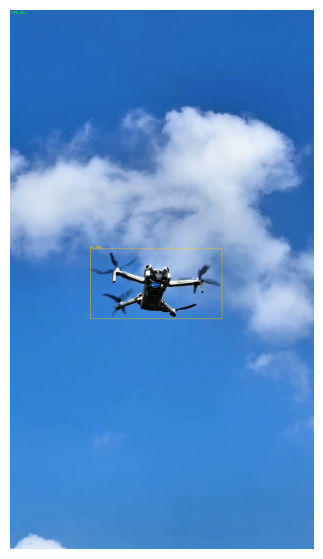

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [28]:
# Takip videosundan bir kare kaydet ve videoyu indir
cap = cv2.VideoCapture('results/tracked.mp4'); n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
cap.set(cv2.CAP_PROP_POS_FRAMES, n // 2); ok, frame = cap.read(); cap.release()
cv2.imwrite('assets/takip_karesi.jpg', frame)
plt.figure(figsize=(12, 7)); plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)); plt.axis('off'); plt.show()
files.download('results/tracked.mp4')

## 5. ONNX'e çevirme ve CPU hız ölçümü
Gömülü cihazlarda (Raspberry Pi, Jetson) genelde ONNX gibi optimize çalışma zamanları kullanılır. Burada CPU'da PyTorch ile ONNX Runtime'ı karşılaştırıyoruz.

In [29]:
!python src/export_benchmark.py --weights $WEIGHTS --images data/drone/test/images --n 100

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs

PyTorch: starting from '/content/drone-detection-tracking/runs/detect/drone_yolo11n/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 5, 8400) (5.3 MB)
requirements: Ultralytics requirement ['onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 10 packages in 265ms
Prepared 2 packages in 28ms
Installed 2 packages in 8ms
 + colorama==0.4.6
 + onnxslim==0.1.99

requirements: AutoUpdate success ✅ 0.7s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: slimming with onnxslim 0.1.99...
ONNX: export success ✅ 3.9

## 6. Sonuçları topla
Aşağıdaki çıktıyı ve `assets/` klasöründeki görselleri README'ye eklemek için kullan.

In [30]:
import json
for f in ['test_metrics.json', 'track_stats.json', 'benchmark.json']:
    p = Path('results') / f
    if p.exists():
        print(f'--- {f}'); print(p.read_text())
!zip -qr sonuclar.zip results assets
files.download('sonuclar.zip')

--- test_metrics.json
{
  "precision": 0.9270673025794216,
  "recall": 0.8280871670702179,
  "mAP50": 0.8894584210880618,
  "mAP50_95": 0.5755194201772895,
  "boyuta_gore": {
    "kucuk (<32px)": {
      "adet": 446,
      "recall": 0.9147982062780269
    },
    "orta (32-96px)": {
      "adet": 710,
      "recall": 0.856338028169014
    },
    "buyuk (>96px)": {
      "adet": 909,
      "recall": 0.8316831683168316
    }
  }
}
--- track_stats.json
{
  "kare_sayisi": 450,
  "iz_sayisi": 1,
  "ortalama_iz_uzunlugu_kare": 450.0,
  "ortalama_fps": 43.2
}
--- benchmark.json
[
  {
    "format": "PyTorch",
    "cihaz": "CPU",
    "ms_goruntu": 117.6,
    "fps": 8.5
  },
  {
    "format": "ONNX Runtime",
    "cihaz": "CPU",
    "ms_goruntu": 99.0,
    "fps": 10.1
  },
  {
    "onnx_boyut_mb": 10.7
  }
]


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [31]:
# Drive'a yedekle (1. hücrede Drive'ı bağladıysan)
import shutil, os
if 'SAVE_DIR' in globals():
    os.makedirs(SAVE_DIR, exist_ok=True)
    for d in ['results', 'assets', str(run_dir)]:
        shutil.copytree(d, os.path.join(SAVE_DIR, Path(d).name), dirs_exist_ok=True)
    print('Kaydedildi:', SAVE_DIR)

Kaydedildi: /content/drive/MyDrive/drone-detection-tracking
